# Теоретические основы нейронных сетей и машинного обучения
# Лабораторная работа №4
# Решающие деревья

В данной лабораторной работе мы попробуем построить дерево руками и рассмотрим некоторые важные для практики технические детали, связанные с построением деревьев.

Загрузите данные о ценах на квартиры в Бостоне.

In [1]:
import pandas as pd
import numpy as np
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]
y = target
x = data

<>:4: SyntaxWarning: invalid escape sequence '\s'
<>:4: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_8590/3094457983.py:4: SyntaxWarning: invalid escape sequence '\s'
  raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)


Можете использовать приложенный файл housing.csv

Описание признаков:

CRIM     per capita crime rate by town


 ZN       proportion of residential land zoned for lots over 25,000 sq.ft.


 INDUS    proportion of non-retail business acres per town


 CHAS     Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)


 NOX      nitric oxides concentration (parts per 10 million)


 RM       average number of rooms per dwelling


 AGE      proportion of owner-occupied units built prior to 1940


 DIS      weighted distances to five Boston employment centres


 RAD      index of accessibility to radial highways


 TAX      full-value property-tax rate per $10,000


 PTRATIO  pupil-teacher ratio by town


 B        1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town


 LSTAT    % lower status of the population


 MEDV     Median value of owner-occupied homes in $1000's

1. (0,5 балла) Постройте гистограмму распределения цен на дома. Сделайте вывод.

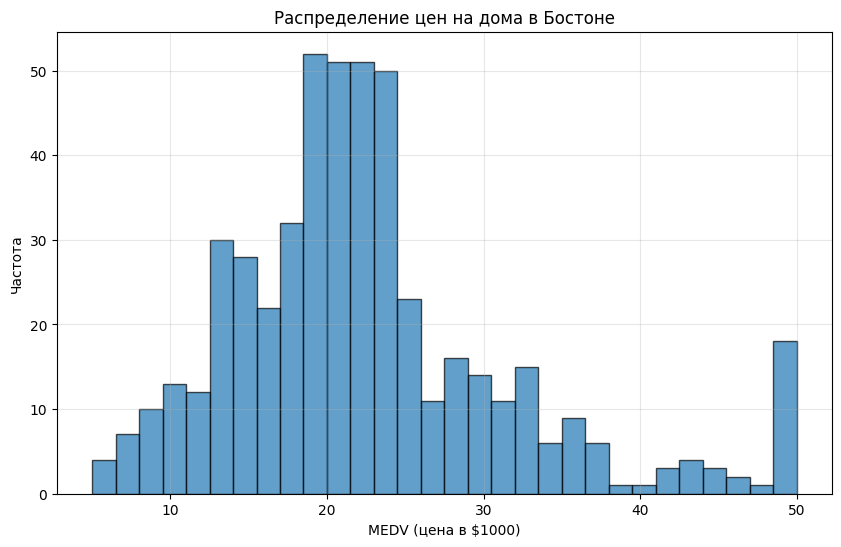

Средняя цена: $22532.81
Медианная цена: $21200.00
Стандартное отклонение: $9188.01


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Построение гистограммы
plt.figure(figsize=(10, 6))
plt.hist(y, bins=30, edgecolor='black', alpha=0.7)
plt.xlabel('MEDV (цена в $1000)')
plt.ylabel('Частота')
plt.title('Распределение цен на дома в Бостоне')
plt.grid(True, alpha=0.3)
plt.show()

# Статистика
print(f"Средняя цена: ${np.mean(y)*1000:.2f}")
print(f"Медианная цена: ${np.median(y)*1000:.2f}")
print(f"Стандартное отклонение: ${np.std(y)*1000:.2f}")

Вывод: Распределение цен на дома имеет асимметрию в области высоких цен. Большинство домов стоят от 15 000 до 25 000 долларов.

2. (0,5 балла) Разбейте выборку на обучающую и тестовую в отношении 3:1.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=42
)

feature_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE',
                 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']
X_train = pd.DataFrame(X_train, columns=feature_names)
X_test = pd.DataFrame(X_test, columns=feature_names)

print(f"Обучающая выборка: {X_train.shape[0]} объектов")
print(f"Тестовая выборка: {X_test.shape[0]} объектов")

Обучающая выборка: 379 объектов
Тестовая выборка: 127 объектов



> "...можно попробовать студентам самим реализовать некоторые алгоритмы вручную, по типу градиентного спуска..." (Пожелания студентов ИСТ-318)



## Решающее дерево своими руками

$R_m$ - множество объектов в разбиваемой вершине, $j$ - номер признака, по которому происходит разбиение, $t$ - порог разбиения.

Критерий ошибки:

$$
Q(R_m, j, t) = \frac{|R_\ell|}{|R_m|}H(R_\ell) + \frac{|R_r|}{|R_m|}H(R_r) \to \min_{j, t}
$$

$R_\ell$ - множество объектов в левом поддереве, $R_r$ - множество объектов в правом поддереве.

$H(R)$ - критерий информативности, с помощью которого можно оценить качество распределения целевой переменной среди объектов множества $R$.

Реализуйте подсчет критерия ошибки. Для этого реализуйте функции для подсчета значения критерия информативности, а также для разбиения вершины.

In [5]:
def H(R):
   return y[R.index].var()

def split_node(R_m, feature, t):
   R_l = R_m[R_m[feature] < t]
   R_r = R_m[R_m[feature] >=t]
   return R_l, R_r

def q_error(R_m, feature, t):
   R_l, R_r = split_node(R_m, feature, t)
   Q = len(R_l) / len(R_m)*H(R_l) + len(R_r) / len(R_m)*H(R_r)
   #print(t, len(R_l), len(R_r), Q )
   return Q

3. (1 балл) Переберите все возможные разбиения выборки по одному из признаков и постройте график критерия ошибки в зависимости от значения порога.Проанализируйте график.

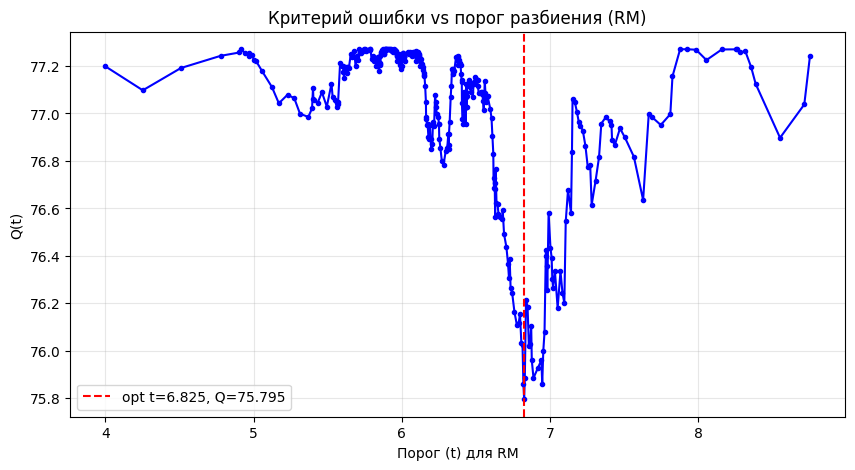

Оптимальный порог: 6.825, Минимальный Q: 75.795


In [8]:
def plot_q_error(R_m, feature):
    values = np.sort(R_m[feature].unique())
    thresholds = (values[:-1] + values[1:]) / 2

    q_errors = [q_error(R_m, feature, t) for t in thresholds]

    plt.figure(figsize=(10, 5))
    plt.plot(thresholds, q_errors, 'b-o', markersize=3)
    plt.xlabel(f'Порог (t) для {feature}')
    plt.ylabel('Q(t)')
    plt.title(f'Критерий ошибки vs порог разбиения ({feature})')
    plt.grid(True, alpha=0.3)

    opt_idx = np.argmin(q_errors)
    plt.axvline(thresholds[opt_idx], color='r', linestyle='--',
                label=f'opt t={thresholds[opt_idx]:.3f}, Q={q_errors[opt_idx]:.3f}')
    plt.legend()
    plt.show()

    return thresholds[opt_idx], q_errors[opt_idx]

# Построить для RM
opt_t, min_q = plot_q_error(X_train, 'RM')
print(f"Оптимальный порог: {opt_t:.3f}, Минимальный Q: {min_q:.3f}")

 График показывает, как меняется качество разбиения в зависимости от выбранного порога. Минимум достигается при пороге 6.825, где дисперсия цен внутри групп минимальна, это означает, что дома с числом комнат менее 6.825 в среднем дешевле, а с числом комнат более 6.825 - дороже.

4. (1 балл) Напишите функцию, находящую оптимальное разбиение данной вершины по данному признаку.

In [9]:
def get_optimal_split(R_m, feature):
    Q_array = []
    feature_values = np.unique(R_m[feature])[1:]
    for t in feature_values:
        Q_array.append(q_error(R_m, feature, t))

    # Находим индекс минимального значения Q
    opt_idx = np.argmin(Q_array)
    opt_threshold = feature_values[opt_idx]

    return opt_threshold, Q_array

5. (1 балл) Постройте графики критерия ошибки (в зависимости от количества объектов в левом поддереве) для каждого из признаков. Найдите признак, показывающий наилучшее качество. Какой это признак? Каков порог разбиения и значение качества? Постройте график критерия ошибки для данного признака в зависимости от значения порога.

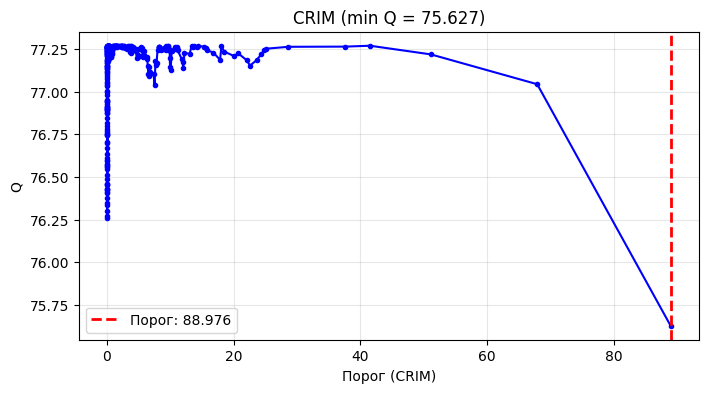

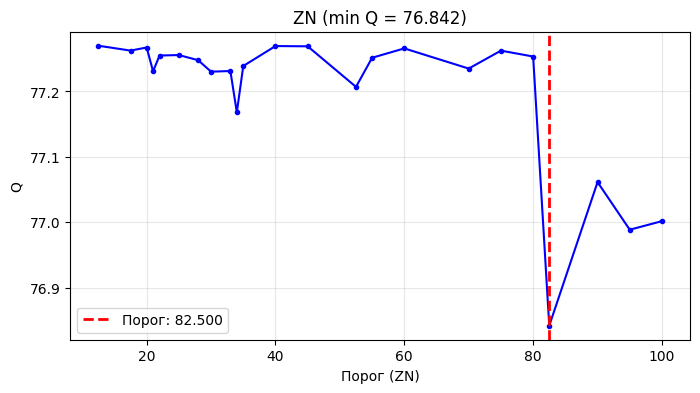

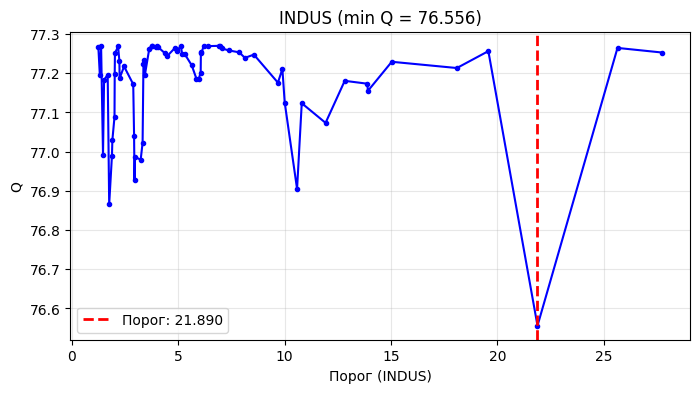

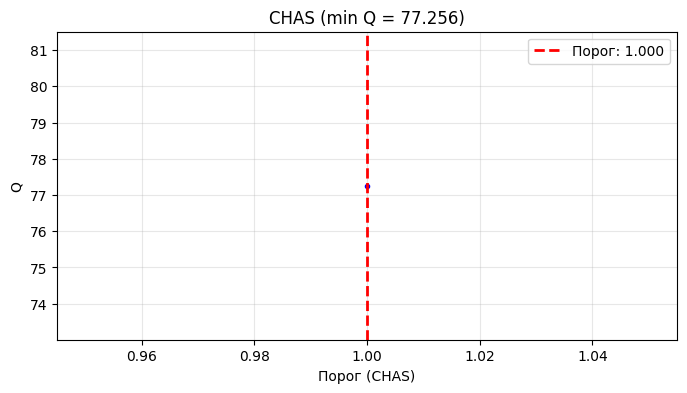

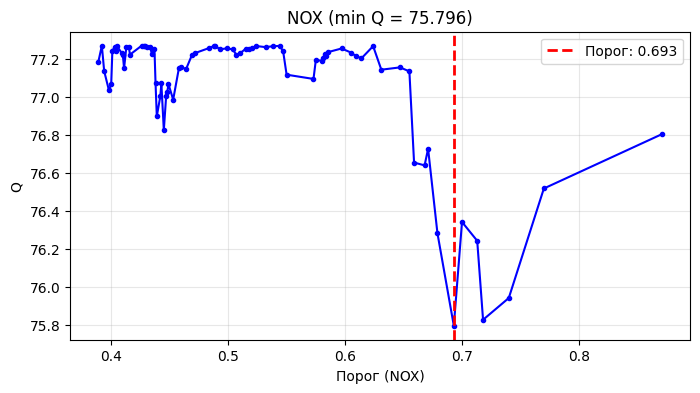

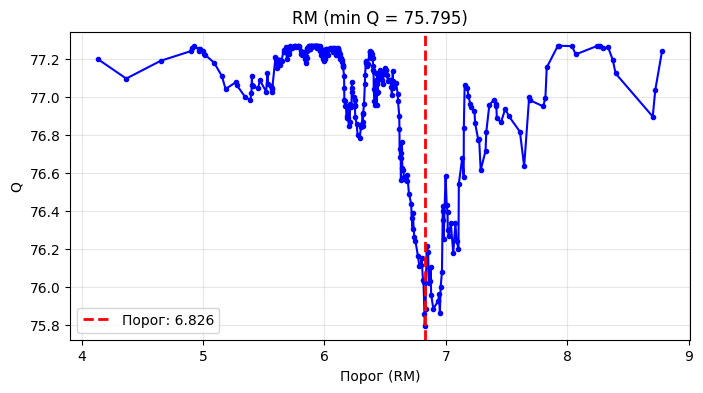

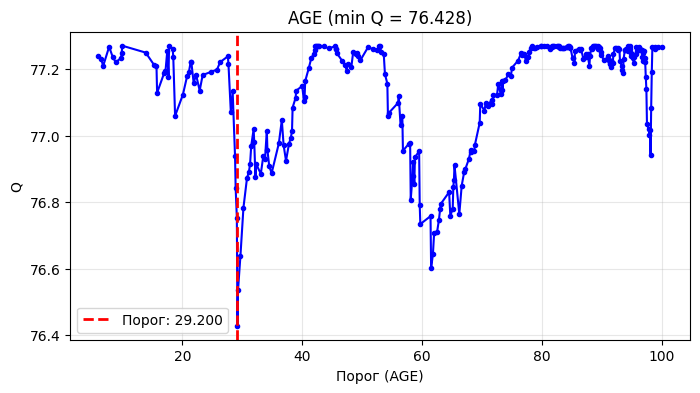

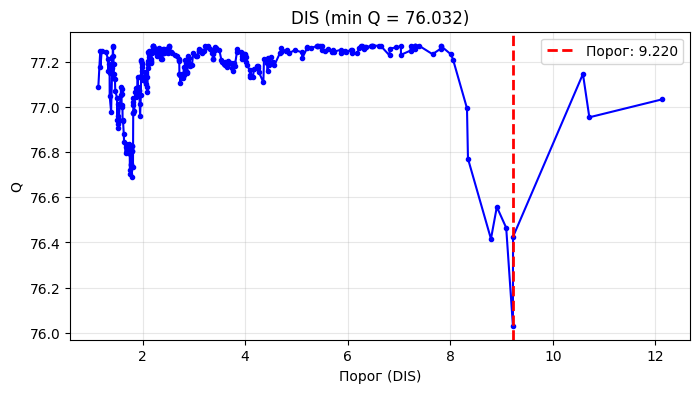

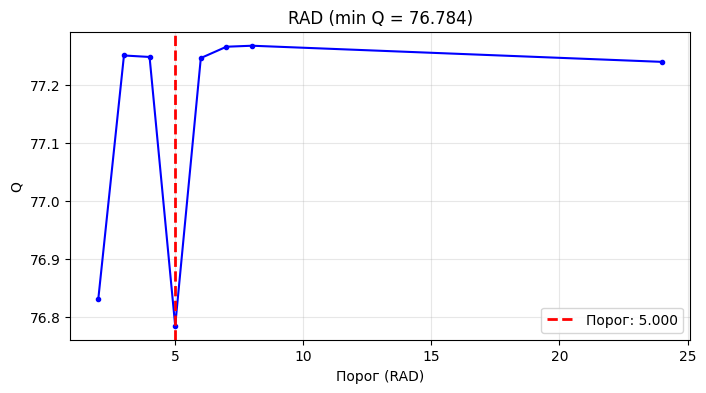

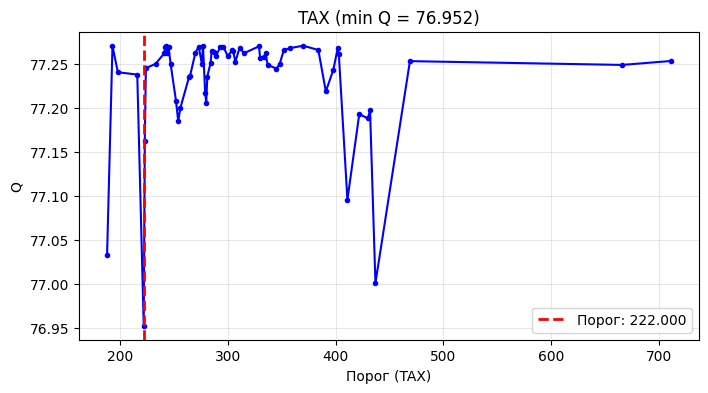

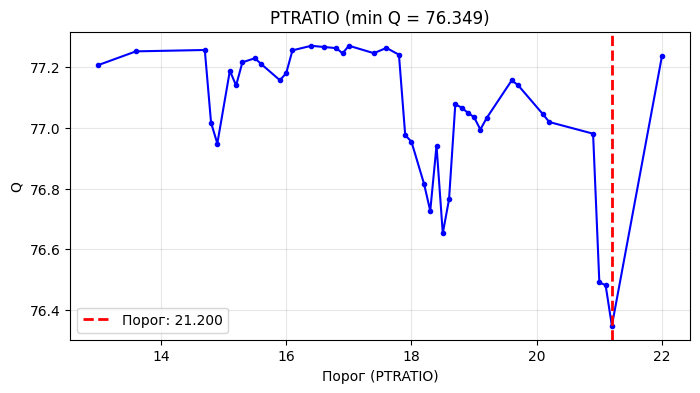

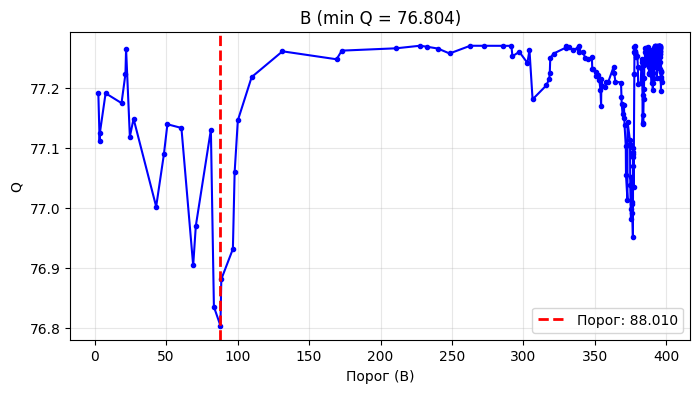

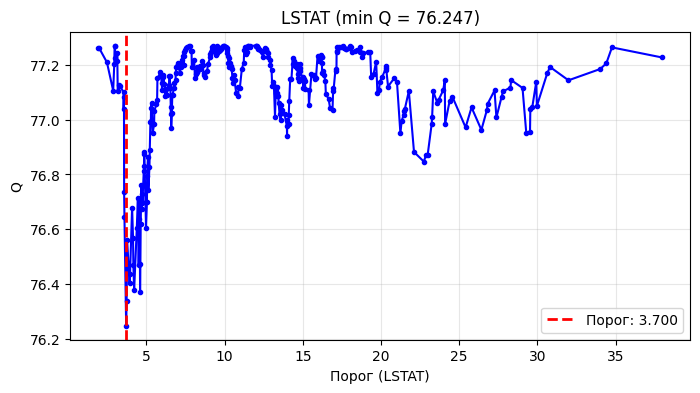


Лучший признак: CRIM
Порог: 88.976
Q: 75.627


In [14]:
for feature in feature_names:
    feature_values = np.unique(X_train[feature])[1:]
    opt_threshold, Q_array = get_optimal_split(X_train, feature)

    plt.figure(figsize=(8, 4))
    plt.plot(feature_values, Q_array, 'b-o', markersize=3)
    plt.axvline(x=opt_threshold, color='r', linestyle='--', linewidth=2,
                label=f'Порог: {opt_threshold:.3f}')
    plt.xlabel(f'Порог ({feature})')
    plt.ylabel('Q')
    plt.title(f'{feature} (min Q = {min(Q_array):.3f})')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# Поиск лучшего признака
results = {}
for feature in feature_names:
    opt_threshold, Q_array = get_optimal_split(X_train, feature)
    results[feature] = min(Q_array)

best_feature = min(results, key=results.get)
opt_threshold, _ = get_optimal_split(X_train, best_feature)

print(f"\nЛучший признак: {best_feature}")
print(f"Порог: {opt_threshold:.3f}")
print(f"Q: {results[best_feature]:.3f}")

Лучшим признаком оказался CRIM (уровень преступности) с порогом 88.976 и качеством Q = 75.627. Это значит, что разбиение по этому признаку лучше всего разделяет дома на дешёвые и дорогие, чем выше преступность, тем ниже цена.

6. (1 балл) Изобразите разбиение визуально. Для этого постройте диаграмму рассеяния целевой переменной в зависимости от значения найденного признака. Далее изобразите вертикальную линию, соответствующую порогу разбиения. Почему это разбиение может быть лучшим? Как вы можете интерпретировать результат?

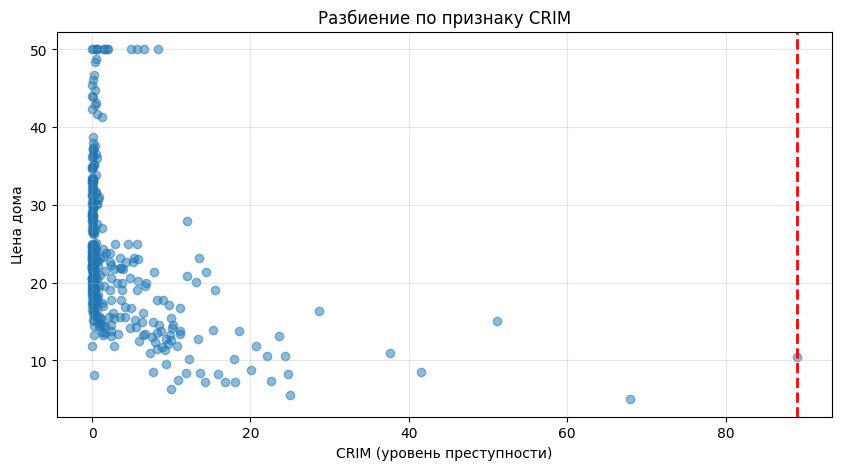

Слева от линии (CRIM < 88.976): дома дороже
Справа от линии (CRIM >= 88.976): дома дешевле
Разбиение лучшее, так как минимален разброс цен внутри групп


In [15]:
best_feature = 'CRIM'
opt_threshold = 88.976

plt.figure(figsize=(10, 5))
plt.scatter(X_train[best_feature], y_train, alpha=0.5)
plt.axvline(x=opt_threshold, color='r', linestyle='--', linewidth=2)
plt.xlabel('CRIM (уровень преступности)')
plt.ylabel('Цена дома')
plt.title('Разбиение по признаку CRIM')
plt.grid(True, alpha=0.3)
plt.show()



## Решающее дерево: sklearn

7. (1 балл) Обучите дерево с помощью DesicionTreeRegressor (max_depth = 3)

In [19]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

dt = DecisionTreeRegressor(max_depth=3, random_state=42)
dt.fit(X_train, y_train)

y_pred_train = dt.predict(X_train)
y_pred_test = dt.predict(X_test)

8. (1 балл) С помощью plot_tree визуализируйте это дерево. Рассчитайте среднюю квадратическую ошибку для дерева.

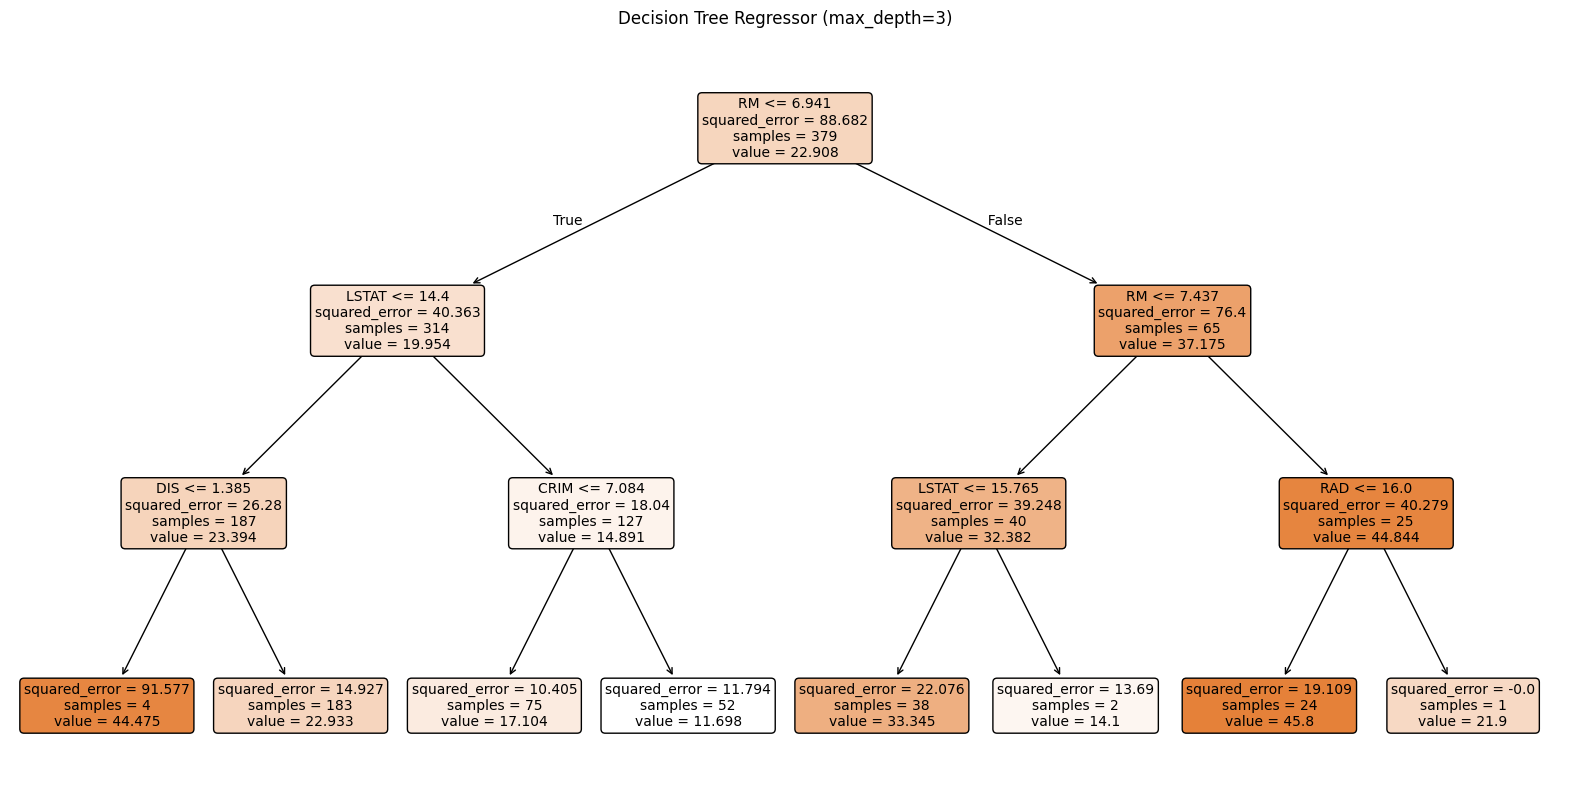

MSE на обучающей выборке: 15.347
MSE на тестовой выборке: 18.333


In [21]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(dt, feature_names=feature_names, filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree Regressor (max_depth=3)')
plt.show()

mse_train = mean_squared_error(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)

print(f"MSE на обучающей выборке: {mse_train:.3f}")
print(f"MSE на тестовой выборке: {mse_test:.3f}")

Подберем гиперпараметры получше.

9. (1 балл) Постройте график зависимости MSE от параметра max_depth и выберите оптимальное значение этого параметра.

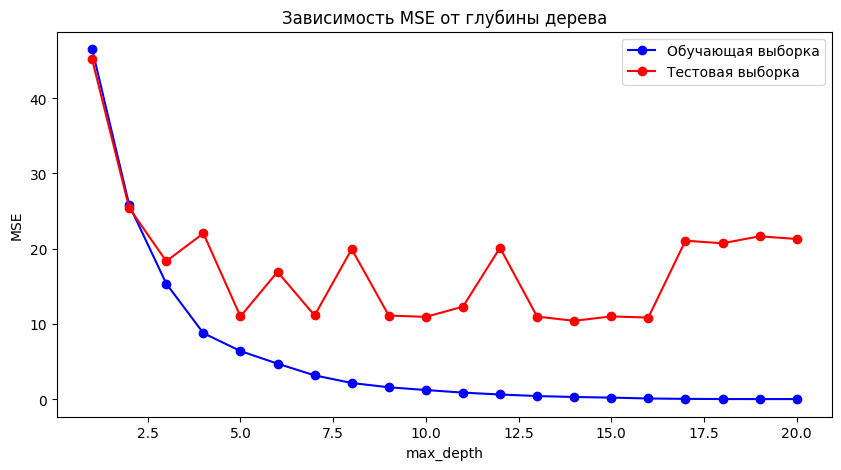

Оптимальное значение max_depth: 14
MSE при opt_depth: 10.406


In [23]:
depths = range(1, 21)
train_mse = []
test_mse = []

for depth in depths:
    dt = DecisionTreeRegressor(max_depth=depth, random_state=42)
    dt.fit(X_train, y_train)
    train_mse.append(mean_squared_error(y_train, dt.predict(X_train)))
    test_mse.append(mean_squared_error(y_test, dt.predict(X_test)))

plt.figure(figsize=(10, 5))
plt.plot(depths, train_mse, 'b-o', label='Обучающая выборка')
plt.plot(depths, test_mse, 'r-o', label='Тестовая выборка')
plt.xlabel('max_depth')
plt.ylabel('MSE')
plt.title('Зависимость MSE от глубины дерева')
plt.legend()
plt.show()

# Оптимальная глубина
opt_depth = depths[np.argmin(test_mse)]
print(f"Оптимальное значение max_depth: {opt_depth}")
print(f"MSE при opt_depth: {min(test_mse):.3f}")

10. (1 балл) Постройте график зависимости MSE от параметра min_samples_leaf и выберите оптимальное значение этого параметра.

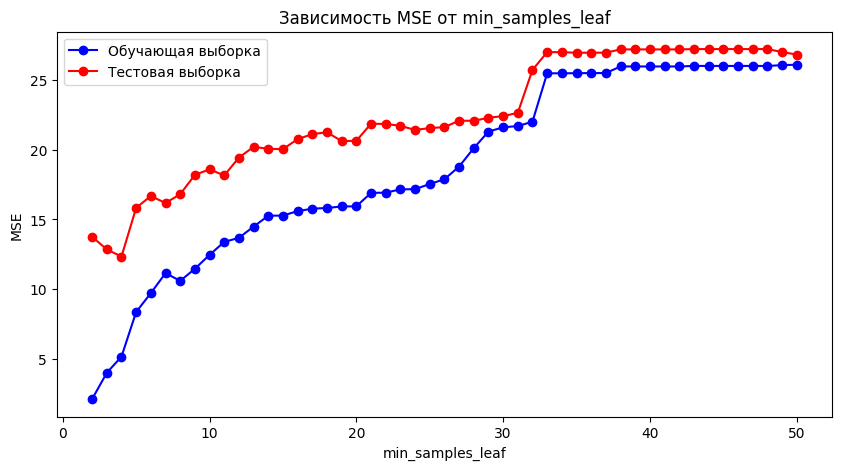

Оптимальное значение min_samples_leaf: 4
MSE при opt_min_samples: 12.342


In [24]:
min_samples_list = range(2, 51)
train_mse = []
test_mse = []

for min_samples in min_samples_list:
    dt = DecisionTreeRegressor(min_samples_leaf=min_samples, random_state=42)
    dt.fit(X_train, y_train)
    train_mse.append(mean_squared_error(y_train, dt.predict(X_train)))
    test_mse.append(mean_squared_error(y_test, dt.predict(X_test)))

plt.figure(figsize=(10, 5))
plt.plot(min_samples_list, train_mse, 'b-o', label='Обучающая выборка')
plt.plot(min_samples_list, test_mse, 'r-o', label='Тестовая выборка')
plt.xlabel('min_samples_leaf')
plt.ylabel('MSE')
plt.title('Зависимость MSE от min_samples_leaf')
plt.legend()
plt.show()

# Оптимальное значение
opt_min_samples = min_samples_list[np.argmin(test_mse)]
print(f"Оптимальное значение min_samples_leaf: {opt_min_samples}")
print(f"MSE при opt_min_samples: {min(test_mse):.3f}")

11. Постройте дерево с оптимальными параметрами и посчитайте важность признаков с помощью метода feature_importances_ .

MSE на тестовой выборке: 12.342


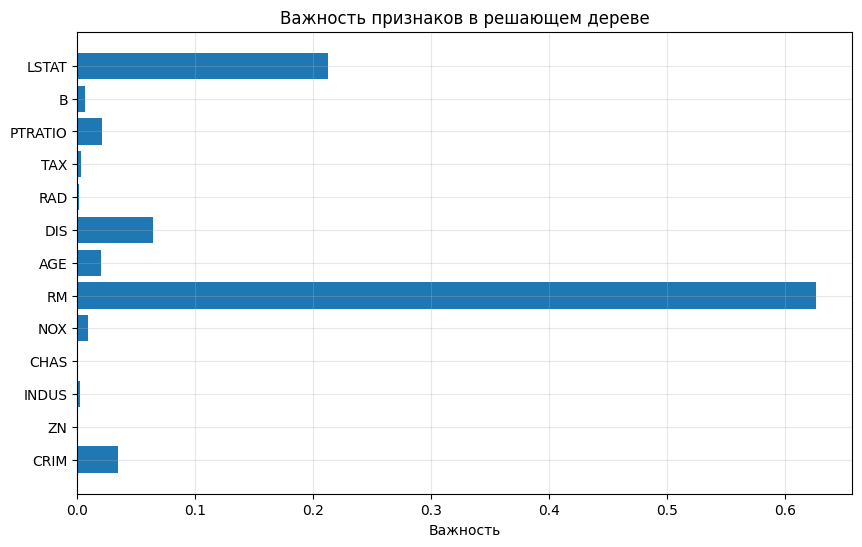

In [26]:
# Обучаем дерево с оптимальными параметрами
dt_optimal = DecisionTreeRegressor(max_depth=14, min_samples_leaf=4, random_state=42)
dt_optimal.fit(X_train, y_train)

# MSE
y_pred = dt_optimal.predict(X_test)
mse_optimal = mean_squared_error(y_test, y_pred)
print(f"MSE на тестовой выборке: {mse_optimal:.3f}")

# Важность признаков
importances = dt_optimal.feature_importances_

# Визуализация важности
plt.figure(figsize=(10, 6))
plt.barh(feature_names, importances)
plt.xlabel('Важность')
plt.title('Важность признаков в решающем дереве')
plt.grid(True, alpha=0.3)
plt.show()

Влияет ли стандартизация (масштабирование) признаков на результат работы решающего дерева?

Нет, не влияет. Решающее дерево принимает решения на основе сравнения значений с порогами.

In [27]:
X_train.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.09103,0.0,2.46,0.0,0.4880,7.155,92.2,2.7006,3.0,193.0,17.8,394.12,4.82
1,3.53501,0.0,19.58,1.0,0.8710,6.152,82.6,1.7455,5.0,403.0,14.7,88.01,15.02
2,0.03578,20.0,3.33,0.0,0.4429,7.820,64.5,4.6947,5.0,216.0,14.9,387.31,3.76
3,0.38735,0.0,25.65,0.0,0.5810,5.613,95.6,1.7572,2.0,188.0,19.1,359.29,27.26
4,0.06724,0.0,3.24,0.0,0.4600,6.333,17.2,5.2146,4.0,430.0,16.9,375.21,7.34


In [28]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train_scaled = pd.DataFrame(sc.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(sc.transform(X_test), columns=X_test.columns, index=X_test.index)
X_train_scaled.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,-0.406795,-0.502812,-1.247076,-0.287849,-0.591174,1.156255,0.833235,-0.503753,-0.740571,-1.280208,-0.205157,0.404512,-1.077756
1,0.007992,-0.502812,1.218283,3.474042,2.628380,-0.238475,0.486246,-0.956440,-0.507741,-0.013937,-1.576252,-3.098037,0.351165
2,-0.413450,0.364381,-1.121792,-0.287849,-0.970291,2.080976,-0.167973,0.441388,-0.507741,-1.141522,-1.487795,0.326591,-1.226252
3,-0.371107,-0.502812,2.092391,-0.287849,0.190598,-0.987986,0.956127,-0.950895,-0.856986,-1.310358,0.369819,0.005983,2.065870
4,-0.409661,-0.502812,-1.134753,-0.287849,-0.826546,0.013216,-1.877617,0.687804,-0.624156,0.148869,-0.603217,0.188141,-0.724729


In [29]:
# without scaling
for max_depth in [3, 6]:
    dt = DecisionTreeRegressor(max_depth=max_depth, random_state=13)
    dt.fit(X_train, y_train)
    print(mean_squared_error(y_test, dt.predict(X_test)))

15.689675955317718
11.749042967178536


In [30]:
# with scaling
for max_depth in [3, 6]:
    dt = DecisionTreeRegressor(max_depth=max_depth, random_state=13)
    dt.fit(X_train_scaled, y_train)
    print(mean_squared_error(y_test, dt.predict(X_test_scaled)))

15.689675955317718
11.749042967178536


Какой вывод можно сделать?



---



Стандартизация (масштабирование) признаков не влияет на результат работы решающего дерева. Это объясняется тем, что деревья решений работают на основе сравнения значений с порогами, и линейное преобразование признаков не меняет порядок и относительные соотношения между значениями. В отличие от линейных моделей или методов, основанных на расстояниях (например, SVM или k-NN), масштабирование для деревьев не требуется.

Сделайте вывод по лабораторной работе. Что вызвало наибольшие затруднения?

В лабораторной работе были реализованы функции для вычисления критерия ошибки, разбиения вершины и поиска оптимального порога. Построены графики зависимости критерия ошибки от порога для всех признаков, определен лучший признак (CRIM) с порогом 88.976. Выполнено обучение решающего дерева с помощью DecisionTreeRegressor, подобраны оптимальные гиперпараметры (max_depth=14, min_samples_leaf=4), рассчитана важность признаков. Показано, что стандартизация признаков не влияет на результат работы решающего дерева. Наибольшие затруднения вызвали понимание критерия ошибки и интерпретация того, почему математически лучший признак может быть бесполезен на практике (отсекает выбросы, а не разделяет основную массу данных).
Наибольшие затруднения вызвали понимание критерия ошибки Q и его вычисление через дисперсию целевой переменной, а также выбор правильных порогов для разбиения (использование середин между уникальными значениями)
